### IPD441 - Visión por Computador
# Clase 13: Diffusion Models
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introduction


<div align="center">
    <img src="img/intro_diffusion.png" alt="" width="60%" align="center" />
</div>

# Diffusion Models

Los modelos generativos de difusión son una forma de generar datos sintéticos basados en un proceso de difusión estocástica. La idea es propagar un conjunto inicial de muestras a través de pasos discretos de tiempo, aplicando pequeñas transformaciones a cada muestra en cada paso. Al hacerlo, las muestras "difunden" a lo largo del tiempo, generando nuevas muestras que se asemejan a las del conjunto inicial pero con variaciones.

<div align="center">
    <img src="img/diffusion_models.png" alt="" width="40%" align="center" />
</div>

# Denoising Diffusion Models (DDM)

La idea central detrás de un modelo de difusión de eliminación de ruido es aplicar ruido aleatorio en una serie de pasos y luego aprender a eliminar el ruido hasta que generar una nueva imagen que parezca extraída del conjunto de entrenamiento.

<div align="center">
    <img src="img/ddm.png" alt="" width="50%" align="center" />
</div>

## The Forward Diffusion Process

Supongamos que tenemos una imagen $\mathbf{x}_0$ que que queremos corromper gradualmente a lo largo de un gran número de pasos (digamos, $T=1000$) de modo que eventualmente sea indistinguible del ruido gaussiano estándar. Podemos definir una función $q$ que agregue una pequeña cantidad de ruido gaussiano con varianza $\beta_t$ a una imagen $\mathbf{x}_{t-1}$ para generar una nueva imagen $\mathbf{x}_t$. Si seguimos aplicando esta función generaremos una secuencia de imágenes progresivamente más ruidosas.

<div align="center">
    <img src="img/forward_diffusion.jpg" alt="" width="100%" align="center" />
</div>

In [1]:
from diffusion_module import *

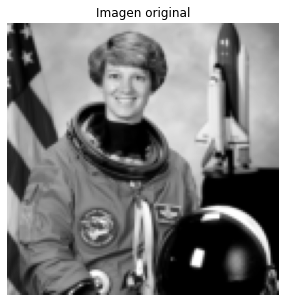

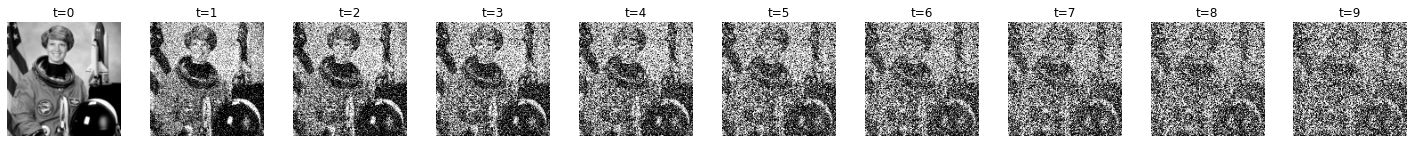

In [2]:
original, noisy_images = forward_diffusion(steps=10, noise_level=0.2)

## Diffusion Schedules

El valor de $\beta_t$ puede variar en cada paso de tiempo, y esto se conoce como "diffusion schedule". En el artículo original (Ho et al., 2020), los autores eligieron un programa de difusión lineal, tal que $\beta$ aumenta linealmente con $t$, desde $\beta_1=0.0001$ a $\beta_T=0.02$. Sin embargo, en un artículo posterior se descubrió que un programa de difusión coseno superaba al programa lineal al agregar ruido a la imagen de manera más gradual.

<div align="center">
    <img src="img/diffusion_schedules.jpg" alt="" width="100%" align="center" />
</div>

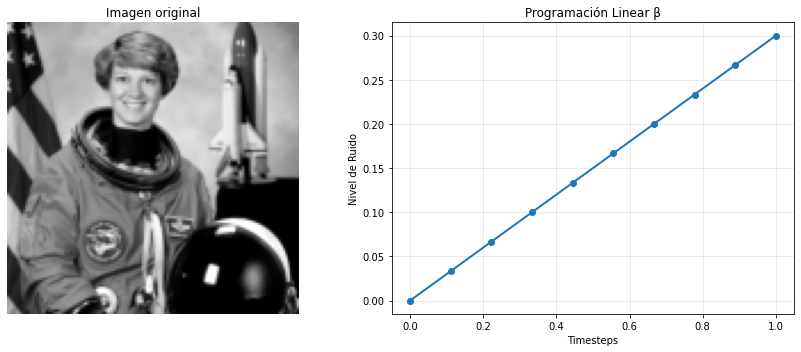

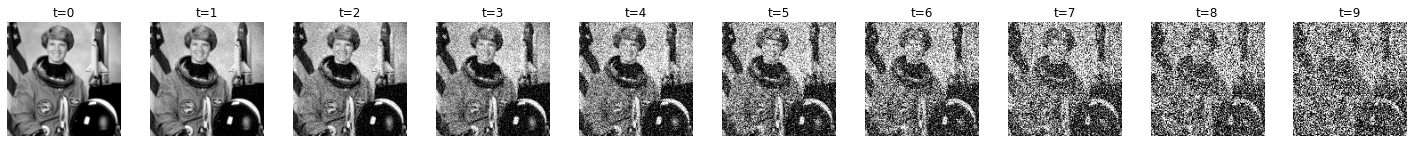

In [3]:
_,_,_ = forward_diffusion_with_schedule(steps=10, schedule_type='linear', max_noise_level=0.3)

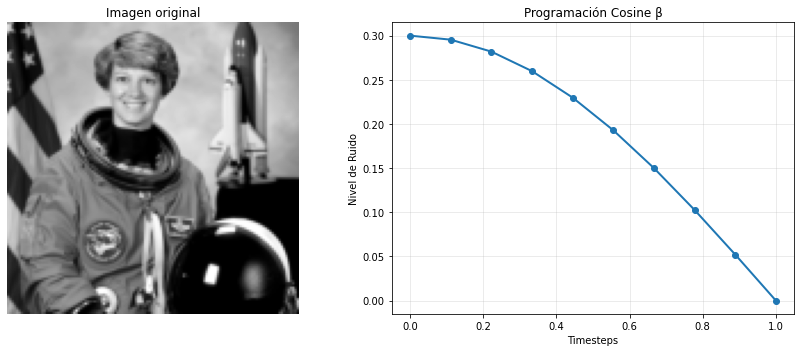

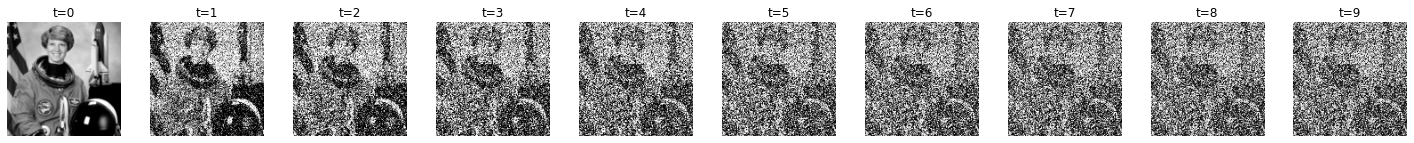

In [4]:
_,_,_ = forward_diffusion_with_schedule(steps=10, schedule_type='cosine', max_noise_level=0.3)

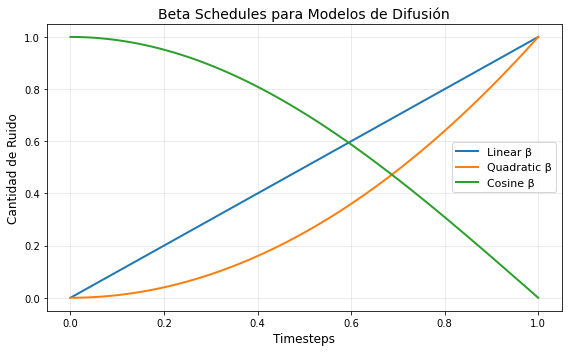

In [5]:
timesteps, linear, quadratic, cosine = plot_beta_schedules()

## The Reverse Diffusion Process

El siguiente paso es aplicar un proceso de difusión a la inversa para eliminar el ruido y generar una imagen nueva a partir de una muestra aleatoria ruidosa. Esto es similar al proceso de decodificación en un VAE.

<div align="center">
    <img src="img/reverse_diffusion.jpg" alt="" width="100%" align="center" />
</div>

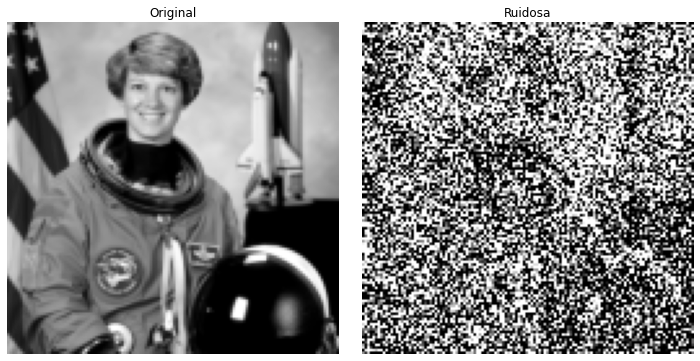

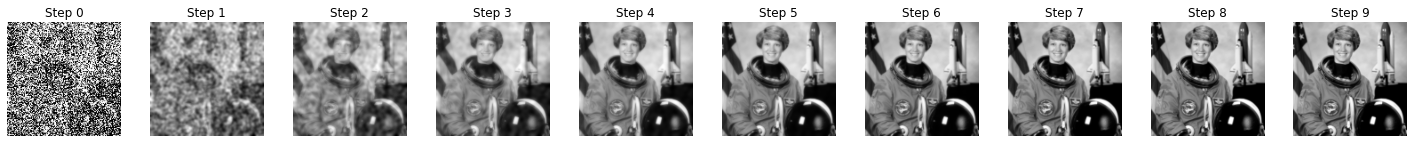

In [6]:
original, noisy, denoised_images = denoising(steps=10)

## The U-Net Denoising Model

<div align="right">
    <img src="img/U-Net.jpg" alt="" width="35%" align="right" />
</div>

Los autores del artículo de DDPM utilizaron un tipo de arquitectura conocida como U-Net para predecir el ruido agregado de la imagen.

Similar al VAE, U-Net consta de dos partes: <tt>**downsampling**</tt>, donde las imágenes de entrada se comprimen espacialmente pero se expanden por canales, y <tt>**upsampling**</tt>, donde las representaciones se expanden espacialmente mientras el número de canales es reducido.

La diferencia con el VAE, es que U-Net no es secuencial, tiene *skip connections* que permite a la información acceder a partes de la red y fluir a capas posteriores.

### ResidualBlock

Tanto el DownBlock como el UpBlock contienen capas de bloques residuales. Un bloque residual es un grupo de capas que contiene una conexión de salto que conecta la entrada con la salida. Los bloques residuales ayudan a construir redes más profundas que pueden aprender patrones más complejos sin sufrir tanto por los problemas de desvanecimiento de gradiente y degradación que sufren redes muy profundas.

<div align="center">
    <img src="img/ResidualBlock.jpg" alt="" width="50%" align="center" />
</div>

### DownBlocks and UpBlocks

<div align="right">
    <img src="img/Down_Up_Blocks.jpg" alt="" width="50%" align="right" />
</div>

Cada <tt>**DownBlock**</tt> sucesivo aumenta el número de canales, aplicando una capa final AveragePooling2D para reducir a la mitad el tamaño de la imagen.

El <tt>**UpBlock**</tt> aplica una capa UpSampling2D que duplica el tamaño de la imagen, mediante interpolación bilineal. Cada UpBlock sucesivo disminuye el número de canales, concatenando las salidas de los DownBlocks a través de conexiones de salto.

## The Flowers Dataset

In [1]:
import matplotlib.pyplot as plt

In [2]:
from ddm import *

In [3]:
IMAGE_SIZE = 64
BATCH_SIZE = 64
DATASET_REPETITIONS = 5

In [4]:
from tensorflow.keras import models, utils, callbacks

In [5]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = utils.get_file('flower_photos', origin=dataset_url, untar=True)

In [6]:
train_data = utils.image_dataset_from_directory(
    data_dir,
    labels=None,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=None,
    shuffle=True,
    seed=42,
    interpolation="bilinear",
)

Found 3670 files belonging to 1 classes.


In [7]:
train = train_data.map(lambda x: preprocess(x))
train = train.repeat(DATASET_REPETITIONS)
train = train.batch(BATCH_SIZE, drop_remainder=True)

In [16]:
noisy_images = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = layers.Conv2D(32, kernel_size=1)(noisy_images)

noise_variances = layers.Input(shape=(1, 1, 1))
noise_embedding = layers.Lambda(sinusoidal_embedding)(noise_variances)
noise_embedding = layers.UpSampling2D(size=IMAGE_SIZE, interpolation="nearest")(
    noise_embedding
)

x = layers.Concatenate()([x, noise_embedding])

skips = []

x = DownBlock(32, block_depth=2)([x, skips])
x = DownBlock(64, block_depth=2)([x, skips])
x = DownBlock(96, block_depth=2)([x, skips])

x = ResidualBlock(128)(x)
x = ResidualBlock(128)(x)

x = UpBlock(96, block_depth=2)([x, skips])
x = UpBlock(64, block_depth=2)([x, skips])
x = UpBlock(32, block_depth=2)([x, skips])

x = layers.Conv2D(3, kernel_size=1, kernel_initializer="zeros")(x)

unet = models.Model([noisy_images, noise_variances], x, name="unet")

In [17]:
unet.summary()

Model: "unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 1, 1, 1)]    0           []                               
                                                                                                  
 input_1 (InputLayer)           [(None, 64, 64, 3)]  0           []                               
                                                                                                  
 lambda (Lambda)                (None, 1, 1, 32)     0           ['input_2[0][0]']                
                                                                                                  
 conv2d (Conv2D)                (None, 64, 64, 32)   128         ['input_1[0][0]']                
                                                                                               

 conv2d_15 (Conv2D)             (None, 16, 16, 96)   83040       ['conv2d_14[0][0]']              
                                                                                                  
 add_5 (Add)                    (None, 16, 16, 96)   0           ['conv2d_15[0][0]',              
                                                                  'add_4[0][0]']                  
                                                                                                  
 average_pooling2d_2 (AveragePo  (None, 8, 8, 96)    0           ['add_5[0][0]']                  
 oling2D)                                                                                         
                                                                                                  
 batch_normalization_6 (BatchNo  (None, 8, 8, 96)    192         ['average_pooling2d_2[0][0]']    
 rmalization)                                                                                     
          

 ormalization)                                                                                    
                                                                                                  
 conv2d_31 (Conv2D)             (None, 32, 32, 64)   73792       ['batch_normalization_11[0][0]'] 
                                                                                                  
 conv2d_32 (Conv2D)             (None, 32, 32, 64)   36928       ['conv2d_31[0][0]']              
                                                                                                  
 conv2d_30 (Conv2D)             (None, 32, 32, 64)   8256        ['concatenate_4[0][0]']          
                                                                                                  
 add_11 (Add)                   (None, 32, 32, 64)   0           ['conv2d_32[0][0]',              
                                                                  'conv2d_30[0][0]']              
          

## Training the Diffusion Model

In [20]:
ddm = DiffusionModel(unet)
ddm.normalizer.adapt(train)

In [ ]:
ddm.built = True
ddm.load_weights("./checkpoint/checkpoint.ckpt")

In [21]:
ddm.compile(
    optimizer=optimizers.experimental.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=losses.mean_absolute_error,
)

In [22]:
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint/checkpoint.ckpt",
    save_weights_only=True,
    save_freq="epoch",
    verbose=0,
)

In [23]:
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [24]:
image_generator_callback = ImageGenerator(num_img=10)

In [25]:
ddm.fit(
    train,
    epochs=20,
    callbacks=[
        model_checkpoint_callback,
        tensorboard_callback,
        image_generator_callback,
    ],
);

Epoch 1/20
286/286 [==============================] - 1273s 4s/step - n_loss: 0.2728
Epoch 2/20
286/286 [==============================] - 1205s 4s/step - n_loss: 0.2143
Epoch 3/20
286/286 [==============================] - 1203s 4s/step - n_loss: 0.2049
Epoch 4/20
286/286 [==============================] - 1214s 4s/step - n_loss: 0.1988
Epoch 5/20
286/286 [==============================] - 1193s 4s/step - n_loss: 0.1952
Epoch 6/20
286/286 [==============================] - 1188s 4s/step - n_loss: 0.1941
Epoch 7/20
286/286 [==============================] - 1241s 4s/step - n_loss: 0.1913
Epoch 8/20
286/286 [==============================] - 1269s 4s/step - n_loss: 0.1904
Epoch 9/20
286/286 [==============================] - 1214s 4s/step - n_loss: 0.1887
Epoch 10/20
286/286 [==============================] - 1233s 4s/step - n_loss: 0.1874
Epoch 11/20
286/286 [==============================] - 1218s 4s/step - n_loss: 0.1866
Epoch 12/20
286/286 [==============================] - 1235s 4s

In [11]:
import os
import ipywidgets as widgets
from IPython.display import display as disp
from PIL import Image  # Import the Image class from PIL

# Folder containing images
folder_path = "output/"

# List all files in the folder
image_files = sorted([file for file in os.listdir(folder_path) 
                      if file.startswith("generated_img_") and file.endswith(".png")])

# Create a function to display the image based on the slider value
def display_image(image_number):
    filename = image_files[image_number - 1]
    img = Image.open(os.path.join(folder_path, filename))
    disp(img)

# Create a slider
image_slider = widgets.IntSlider(min=1, max=len(image_files), description='Epoch:')
initial_image_number = 1

In [12]:
widgets.interact(display_image, image_number=image_slider);

interactive(children=(IntSlider(value=1, description='Epoch:', max=20, min=1), Output()), _dom_classes=('widge…

## Sampling from the Denoising Diffusion Model

Para generar imágenes usando el modelo entrenado, debemos aplicar el proceso de difusión inversa, es decir, comenzar con ruido aleatorio y usar el modelo para deshacer gradualmente el ruido, hasta que nos quede una imagen reconocible. Sin embargo, no es conveniente deshacer el ruido de una vez, sino gradualmente en muchos pasos pequeños, para permitir que el modelo se ajuste a sus propias predicciones. Somos libres de elegir el número de pasos que damos y puede ser mucho menor que en el entrenamiento.

<div align="center">
    <img src="img/sampling.jpg" alt="" width="80%" align="center" />
</div>

### Generating images

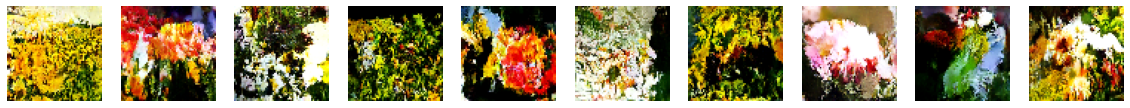

In [29]:
generated_images = ddm.generate(num_images=10, diffusion_steps=20).numpy()
display(generated_images)

### Adjusting the number of diffusion steps

También podemos probar para ver cómo el ajuste del número de pasos de difusión en el proceso inverso afecta la calidad de la imagen. Intuitivamente, cuantos más pasos en el proceso, mayor será la calidad de la imágenes generadas. Sin embargo, el tiempo necesario para generar las imágenes aumenta linealmente con el número de pasos de difusión, por lo que existe un trade-off.

In [31]:
def plot_diffusion_steps(diffusion_steps):
    tf.random.set_seed(42)
    for step in diffusion_steps:
        generated_images = ddm.generate(
            num_images=10,
            diffusion_steps=step,
        ).numpy()
        display(generated_images)

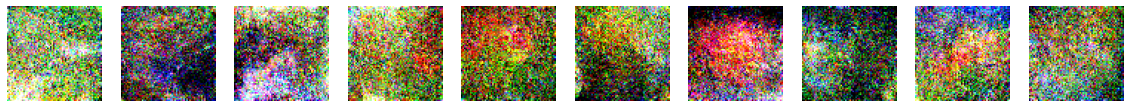

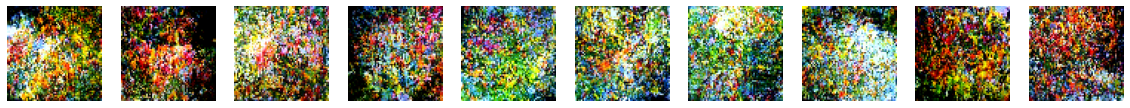

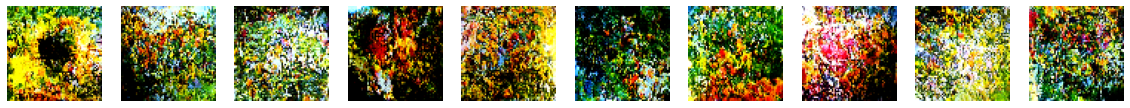

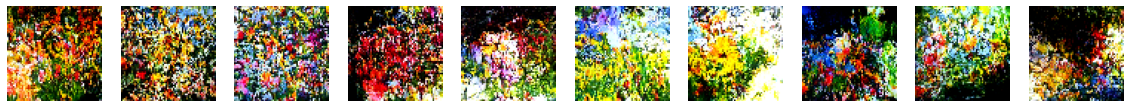

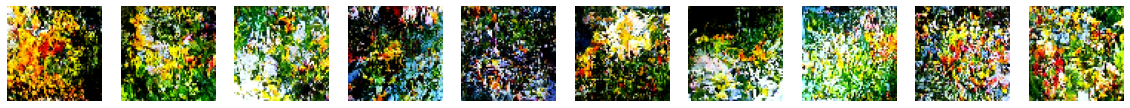

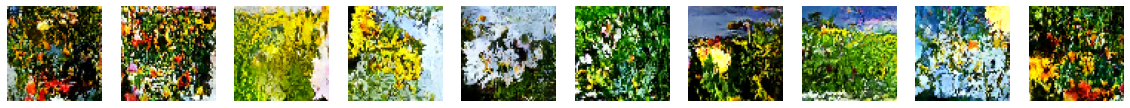

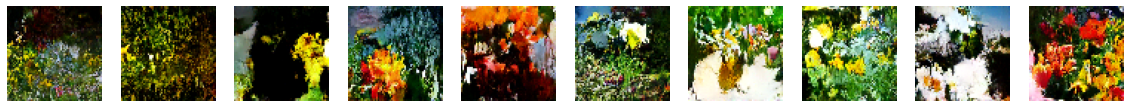

In [32]:
plot_diffusion_steps(list(np.arange(1, 6, 1)) + [20] + [100])

### Interpolating between images

Por último, como hemos visto anteriormente, podemos interpolar entre puntos en el espacio latente gaussiano para realizar una transición suave entre imágenes en el espacio de píxeles. Aquí elegimos utilizar una forma de interpolación esférica que garantiza que la varianza permanezca constante mientras combinamos los dos mapas de ruido gaussianos.

In [33]:
def plot_interpolation(nrows=5, ncols=11):
    tf.random.set_seed(100)
    for i in range(nrows):
        a = tf.random.normal(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
        b = tf.random.normal(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
        initial_noise = np.array(
            [spherical_interpolation(a, b, t) for t in np.arange(0, 1.1, 0.1)]
        )
        generated_images = ddm.generate(
            num_images=2, diffusion_steps=20, initial_noise=initial_noise
        ).numpy()
        display(generated_images, n=ncols)

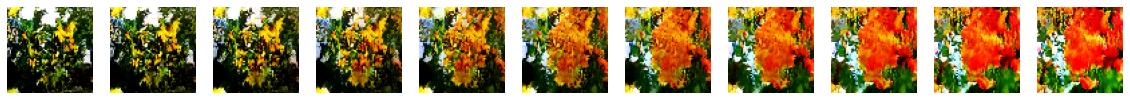

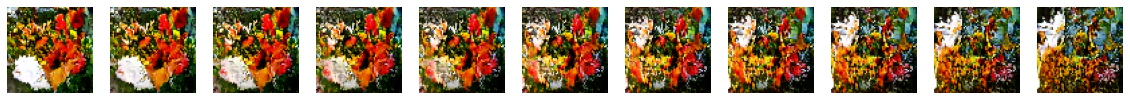

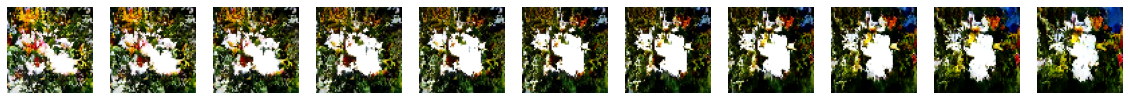

In [34]:
plot_interpolation(nrows=3, ncols=11)

# Implementación del proceso de difusión usando Hugging Face Diffusers

- El pipeline `DDPMPipeline`, diseñado para modelos Denoising Diffusion Probabilistic Models (DDPM), permite cargar un modelo preentrenado, configurar el número de pasos de inferencia y generar una imagen a partir de ruido puro.
- El modelo utilizado en esta demostración es `google/ddpm-celebahq-256`, el cual fue entrenado sobre el dataset CelebA-HQ.

In [1]:
import torch
import matplotlib.pyplot as plt
from diffusers import DDPMPipeline
from tqdm import tqdm

In [13]:
def generate_and_plot_diffusion(
    model_name="google/ddpm-celebahq-256", 
    num_steps_to_show=6, num_inference_steps=1000, seed=None):
    
    # Opcional: fijar semilla
    if seed is not None:
        torch.manual_seed(seed)
    
    # Cargar modelo
    device = "cuda" if torch.cuda.is_available() else "cpu"
    pipeline = DDPMPipeline.from_pretrained(model_name).to(device)
    
    # Preparar ruido inicial
    noise = torch.randn(
        (1, pipeline.unet.config.in_channels, pipeline.unet.config.sample_size, pipeline.unet.config.sample_size)
    ).to(device)
    
    # Configurar scheduler
    scheduler = pipeline.scheduler
    scheduler.set_timesteps(num_inference_steps)
    
    # Lista para guardar imágenes y sus timesteps
    images = []
    timestep_labels = []
    
    timesteps_to_store = torch.linspace(0, scheduler.num_inference_steps - 1, steps=num_steps_to_show).long()
    
    with torch.no_grad():
        latents = noise
        for i, t in enumerate(tqdm(scheduler.timesteps)):
            model_output = pipeline.unet(latents, t).sample
            latents = scheduler.step(model_output, t, latents).prev_sample
            
            if i in timesteps_to_store.tolist():
                image = (latents[0] / 2 + 0.5).clamp(0, 1)
                images.append(image.cpu())
                timestep_labels.append(int(t.item()))
    
    # Última imagen
    final_image = (latents[0] / 2 + 0.5).clamp(0, 1)
    images.append(final_image.cpu())
    timestep_labels.append(0)
    
    # Mostrar resultados
    fig, axs = plt.subplots(1, len(images), figsize=(3 * len(images), 3))
    for idx, (img, label) in enumerate(zip(images, timestep_labels)):
        axs[idx].imshow(img.permute(1, 2, 0))
        axs[idx].axis("off")
        axs[idx].set_title(f"t={label}")
    
    plt.tight_layout()
    plt.show()

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [1:42:29<00:00,  6.15s/it]


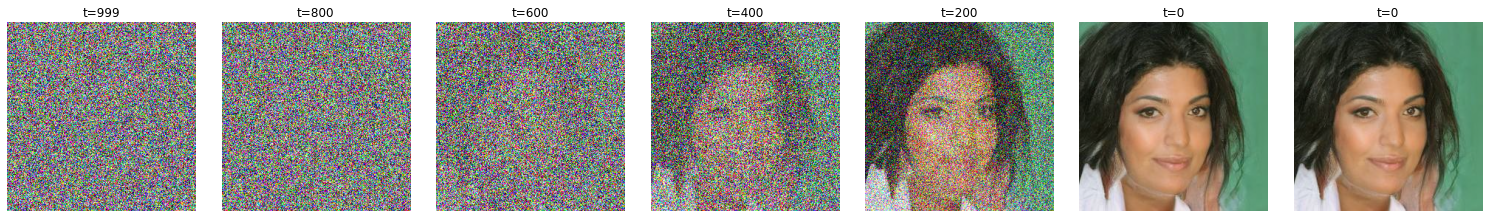

In [14]:
generate_and_plot_diffusion(model_name="google/ddpm-celebahq-256", num_inference_steps=1000)

# Interpolación en el Espacio Latente de Ruido

En los DDPM, el ruido inicial es solo una semilla para la muestra generada, pero pequeños cambios en el ruido pueden llevar a resultados totalmente distintos, por lo que interpolar ruido no garantiza interpolación visual suave.

<div align="center">
    <img src="img/slerp.png" alt="" width="30%" align="center" />
</div>

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from diffusers import DDPMPipeline
from tqdm import tqdm

In [2]:
def spherical_interpolation(a, b, t):
    a_norm = a / torch.norm(a)
    b_norm = b / torch.norm(b)
    omega = torch.acos((a_norm * b_norm).sum())
    so = torch.sin(omega)
    if so == 0:
        return (1.0 - t) * a + t * b
    return (torch.sin((1.0 - t) * omega) / so) * a + (torch.sin(t * omega) / so) * b


def interpolate_faces(
    model_name="google/ddpm-celebahq-256",
    num_steps=11,
    num_inference_steps=1000,
    seed=None,
):
    if seed is not None:
        torch.manual_seed(seed)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    pipe = DDPMPipeline.from_pretrained(model_name).to(device)
    scheduler = pipe.scheduler
    scheduler.set_timesteps(num_inference_steps)

    # Dimensiones del ruido
    shape = (1, 
             pipe.unet.config.in_channels, 
             pipe.unet.config.sample_size, 
             pipe.unet.config.sample_size)

    # Dos vectores de ruido de inicio y fin
    noise_a = torch.randn(shape).to(device)
    noise_b = torch.randn(shape).to(device)

    # Interpolaciones
    interpolated_noises = [spherical_interpolation(noise_a[0], 
                                                   noise_b[0], 
                                                   t) for t in np.linspace(0, 
                                                                           1, 
                                                                           num_steps)]

    # Generar imágenes
    images = []
    with torch.no_grad():
        for z in tqdm(interpolated_noises):
            latents = z.unsqueeze(0).to(device)
            for t in scheduler.timesteps:
                model_output = pipe.unet(latents, t).sample
                latents = scheduler.step(model_output, t, latents).prev_sample
            image = (latents[0] / 2 + 0.5).clamp(0, 1).cpu()
            images.append(image)

    # Mostrar
    fig, axs = plt.subplots(1, num_steps, figsize=(3 * num_steps, 3))
    for i, img in enumerate(images):
        axs[i].imshow(img.permute(1, 2, 0))
        axs[i].axis("off")
        axs[i].set_title(f"t={i}")
    plt.tight_layout()
    plt.show()

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 11/11 [29:21:56<00:00, 9610.62s/it]   


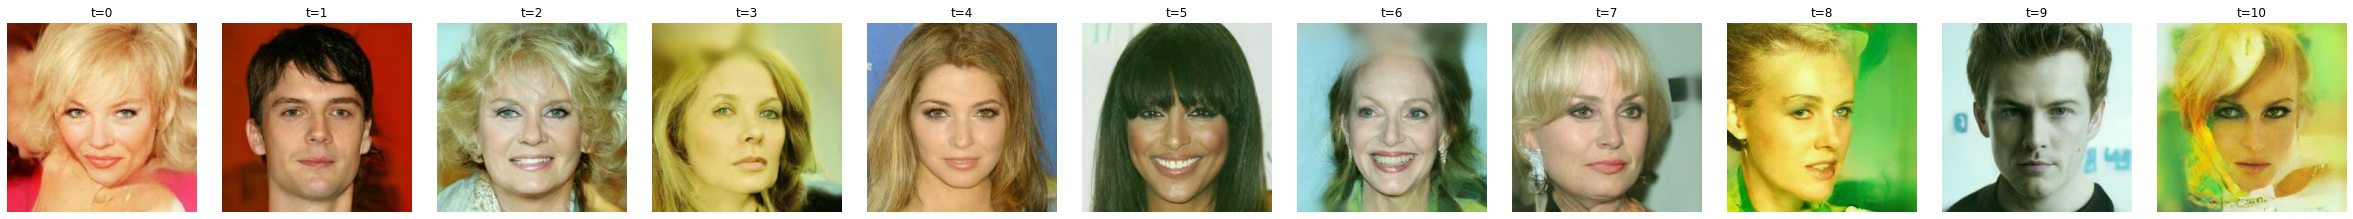

In [4]:
interpolate_faces(model_name="google/ddpm-celebahq-256", num_steps=11, num_inference_steps=1000)